In [1]:
import pandas as pd
from transformers import pipeline, AutoTokenizer

# Cargar el archivo CSV
df = pd.read_csv('datos_corregidos - copia.csv')

# Nombre de la columna de texto
texto_columna = 'cuerpoReseña'
titulo_columna = 'títuloReseña'

# Inicializar el pipeline de análisis de sentimientos con un modelo específico
modelo = 'nlptown/bert-base-multilingual-uncased-sentiment'
analisis_sentimientos = pipeline('sentiment-analysis', model=modelo)

# Inicializar el tokenizer
tokenizer = AutoTokenizer.from_pretrained(modelo)

# Longitud máxima de secuencia permitida por el modelo
max_length = tokenizer.model_max_length

# Función para mapear las etiquetas numéricas a etiquetas descriptivas
def mapear_etiqueta(label):
    mapping = {
        '1 star': 'Muy Negativo',
        '2 stars': 'Negativo',
        '3 stars': 'Neutro',
        '4 stars': 'Positivo',
        '5 stars': 'Muy Positivo'
    }
    return mapping.get(label, 'Neutro')

# Función para analizar los sentimientos de cada texto con truncamiento
def obtener_sentimiento(texto):
    # Truncar el texto si es más largo que la longitud máxima permitida
    tokens = tokenizer(texto, truncation=True, max_length=max_length)
    texto_truncado = tokenizer.decode(tokens['input_ids'], skip_special_tokens=True)
    resultado = analisis_sentimientos(texto_truncado)[0]
    etiqueta = mapear_etiqueta(resultado['label'])
    return etiqueta, resultado['score']

# Aplicar el análisis de sentimientos a cada texto en el DataFrame
df['sentimiento'], df['puntaje'] = zip(*df[texto_columna].apply(obtener_sentimiento))
df['sentimiento_titulo'],df['puntaje_titulo'] = zip(*df[titulo_columna].apply(obtener_sentimiento))


# Mostrar los resultados
print(df[['cuerpoReseña', 'sentimiento', 'puntaje', 'títuloReseña','sentimiento_titulo','puntaje_titulo']].head())

# Guardar los resultados en un nuevo archivo CSV
resultado_path = 'resultados_analisis_sentimientos.csv'
df.to_csv(resultado_path, index=False)

print(f"Análisis de sentimientos completado. Los resultados se han guardado en: {resultado_path}")


c:\Users\yeiso\myenv\Lib\site-packages\huggingface_hub\file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(



                                        cuerpoReseña   sentimiento   puntaje  \
0  Es triste saber que aún existen lugares como e...  Muy Negativo  0.632372   
1   Una muy buena opción para disfrutar por su va...      Negativo  0.276271   
2  El lugar es cómodo y agradable, cerca a Medell...        Neutro  0.479760   
3  Esta fue una recomendación fantástica de un am...  Muy Positivo  0.644674   
4   Muy lindo entorno, paisajes realmente bellos,...        Neutro  0.295234   

                                        títuloReseña sentimiento_titulo  \
0                     La peor estadía de mi vida!!!!       Muy Negativo   
1   El servicio tan malo que oscurece un lugar ta...       Muy Negativo   
2   Buen lugar, cercano a Medellín pero la comida...           Positivo   
3             Paz real y tranquilidad lejos de todo.       Muy Positivo   
4   Entorno espectacular, paisajes maravillosos, ...       Muy Positivo   

   puntaje_titulo  
0        0.912182  
1        0.763212  
2      

In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Resumen estadístico de los sentimientos
sentiment_summary = data['sentimiento'].value_counts().reset_index()
sentiment_summary.columns = ['sentimiento', 'frecuencia']

# Relación entre la calificación y el sentimiento
rating_sentiment_relation = data.groupby(['calificaciónReseña', 'sentimiento']).size().unstack(fill_value=0)

# Gráfico de la Distribución de Sentimientos
fig1 = px.bar(sentiment_summary, x='sentimiento', y='frecuencia', 
              color='sentimiento', title='Distribución de Sentimientos',
              labels={'frecuencia': 'Frecuencia', 'sentimiento': 'Sentimiento'})

# Mostrar el gráfico
fig1.show()

# Preparar datos para el gráfico de la relación entre calificación y sentimiento
rating_sentiment_relation = rating_sentiment_relation.reset_index()
rating_sentiment_relation_melted = rating_sentiment_relation.melt(id_vars='calificaciónReseña', 
                                                                  var_name='sentimiento', value_name='frecuencia')

# Gráfico de la Relación entre Calificación y Sentimiento
fig2 = px.bar(rating_sentiment_relation_melted, x='calificaciónReseña', y='frecuencia', color='sentimiento',
              title='Relación entre Calificación y Sentimiento', 
              labels={'frecuencia': 'Frecuencia', 'calificaciónReseña': 'Calificación'},
              barmode='stack')

# Mostrar el gráfico
fig2.show()

# Resumen estadístico de los sentimientos
sentiment_summary


,sentimiento,frecuencia
0,Muy Positivo,1152
1,Positivo,284
2,Neutro,87
3,Negativo,78
4,Muy Negativo,59


In [3]:
import pandas as pd
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Resumen estadístico de los sentimientos de los títulos
sentiment_summary_titulo = data['sentimiento_titulo'].value_counts().reset_index()
sentiment_summary_titulo.columns = ['sentimiento_titulo', 'frecuencia']

# Relación entre la calificación y el sentimiento de los títulos
rating_sentiment_relation_titulo = data.groupby(['calificaciónReseña', 'sentimiento_titulo']).size().unstack(fill_value=0)

# Gráfico de la Distribución de Sentimientos de los Títulos
fig1 = px.bar(sentiment_summary_titulo, x='sentimiento_titulo', y='frecuencia', 
              color='sentimiento_titulo', title='Distribución de Sentimientos de los Títulos',
              labels={'frecuencia': 'Frecuencia', 'sentimiento_titulo': 'Sentimiento de los Títulos'})

# Mostrar el gráfico
fig1.show()

# Preparar datos para el gráfico de la relación entre calificación y sentimiento de los títulos
rating_sentiment_relation_titulo = rating_sentiment_relation_titulo.reset_index()
rating_sentiment_relation_titulo_melted = rating_sentiment_relation_titulo.melt(id_vars='calificaciónReseña', 
                                                                                var_name='sentimiento_titulo', value_name='frecuencia')

# Gráfico de la Relación entre Calificación y Sentimiento de los Títulos
fig2 = px.bar(rating_sentiment_relation_titulo_melted, x='calificaciónReseña', y='frecuencia', color='sentimiento_titulo',
              title='Relación entre Calificación y Sentimiento de los Títulos', 
              labels={'frecuencia': 'Frecuencia', 'calificaciónReseña': 'Calificación'},
              barmode='stack')

# Mostrar el gráfico
fig2.show()

# Resumen estadístico de los sentimientos de los títulos
sentiment_summary_titulo


,sentimiento_titulo,frecuencia
0,Muy Positivo,1222
1,Positivo,194
2,Muy Negativo,129
3,Neutro,76
4,Negativo,39


In [4]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Distribución de los sentimientos por municipio
municipality_sentiment_distribution = data.groupby(['municipio', 'sentimiento']).size().unstack(fill_value=0)

# Mostrar la tabla numérica
print(municipality_sentiment_distribution)

# Visualización de la distribución de sentimientos en cada municipio
municipality_sentiment_distribution = municipality_sentiment_distribution.reset_index()
municipality_sentiment_distribution_melted = municipality_sentiment_distribution.melt(id_vars='municipio', 
                                                                                      var_name='sentimiento', value_name='frecuencia')

fig1 = px.bar(municipality_sentiment_distribution_melted, x='municipio', y='frecuencia', color='sentimiento', 
              title='Distribución de Sentimientos por Municipio', 
              labels={'frecuencia': 'Frecuencia', 'municipio': 'Municipio'}, 
              barmode='stack')

# Mostrar el gráfico
fig1.show()

# Crear una tabla fuera del gráfico
header_values = list(municipality_sentiment_distribution.columns)
cell_values = [municipality_sentiment_distribution[col].tolist() for col in municipality_sentiment_distribution.columns]

fig2 = go.Figure(data=[go.Table(
    header=dict(values=header_values,
                fill_color='paleturquoise',
                align='left'),
    cells=dict(values=cell_values,
               fill_color='lavender',
               align='left'))
])

fig2.update_layout(
    title='Tabla de Distribución de Sentimientos por Municipio',
    height=400
)

# Mostrar la tabla
fig2.show()


sentimiento     Muy Negativo  Muy Positivo  Negativo  Neutro  Positivo
municipio                                                             
Amagá                      3             3        10       5         8
Andes                      2            66         1       2        16
Caramanta                  0             1         0       0         0
Ciudad Bolívar             1            18         2       1        15
Fredonia                   0            44         1       1         5
Jardín                    24           318        35      39       104
Jericó                    14           539        11      25        88
La Pintada                 9            52        12      10        29
Santa Bárbara              0             3         2       1         0
Támesis                    3            43         4       1        12
Urrao                      3            25         0       1         7
Venecia                    0            40         0       1         0


In [5]:
import pandas as pd
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Calificación promedio por sentimiento para cada entidad (columna 'nombre') y municipio
average_rating_by_sentiment_entity_municipality = data.groupby(['municipio', 'nombre', 'sentimiento'])['calificaciónReseña'].mean().unstack()

# Mostrar la tabla de calificación promedio por sentimiento para cada entidad y municipio
print(average_rating_by_sentiment_entity_municipality)

# Crear un gráfico para cada municipio
municipios = average_rating_by_sentiment_entity_municipality.index.get_level_values('municipio').unique()

for municipio in municipios:
    df_municipio = average_rating_by_sentiment_entity_municipality.loc[municipio].reset_index()
    df_municipio_melted = df_municipio.melt(id_vars='nombre', var_name='sentimiento', value_name='calificaciónPromedio')
    
    fig = px.bar(df_municipio_melted, x='nombre', y='calificaciónPromedio', color='sentimiento', 
                 title=f'Calificación Promedio por Sentimiento para {municipio}', 
                 labels={'calificaciónPromedio': 'Calificación Promedio', 'nombre': 'Entidad'}, 
                 barmode='stack', 
                 color_discrete_map={'Muy Negativo': 'red', 'Negativo': 'orange', 'Neutro': 'gray', 'Positivo': 'blue', 'Muy Positivo': 'green'})

    # Ajustar el diseño del gráfico
    fig.update_layout(
        xaxis_title='Entidad',
        yaxis_title='Calificación Promedio',
        legend_title='Sentimiento',
        legend=dict(x=1, xanchor='left')
    )

    # Mostrar el gráfico
    fig.show()


sentimiento                            Muy Negativo  Muy Positivo  Negativo  \
municipio nombre                                                              
Amagá      El Rancherito                        NaN           NaN  1.000000   
           Hotel Hacienda La Bonita        1.333333           4.5  2.333333   
           La Curva del Gordo - Amagá           NaN           5.0       NaN   
Andes      Café La Traviesa                     NaN           NaN       NaN   
           Café Premontano - Vivero             NaN           5.0       NaN   
...                                             ...           ...       ...   
Venecia    Hotel Casa Luna                      NaN           5.0       NaN   
           Manantiales de Cerro Tusa            NaN           5.0       NaN   
           Restaurante La Graciela              NaN           5.0       NaN   
          Hotel Casa Luna                       NaN           5.0       NaN   
          Manantiales de Cerro Tusa             NaN 

In [6]:
import pandas as pd
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Distribución de los sentimientos por municipio
municipality_sentiment_distribution = data.groupby(['municipio', 'sentimiento']).size().unstack(fill_value=0)

# Calcular el promedio de sentimientos por municipio
municipality_sentiment_avg = municipality_sentiment_distribution.mean(axis=0)

# Calcular el total de sentimientos por municipio
municipality_sentiment_distribution['total'] = municipality_sentiment_distribution.sum(axis=1)

# Preparar datos para Plotly
municipality_sentiment_distribution['municipio'] = municipality_sentiment_distribution.index
long_df = municipality_sentiment_distribution.melt(id_vars=['municipio', 'total'], var_name='sentimiento', value_name='cantidad')

# Crear el gráfico de burbujas
fig = px.scatter(long_df, x='sentimiento', y='cantidad', size='total', color='municipio',
                 hover_name='municipio', size_max=60,
                 labels={'cantidad': 'Promedio de Sentimientos', 'sentimiento': 'Sentimientos'},
                 title='Promedio de Sentimientos por Municipio (Gráfico de Burbujas)')

# Mostrar el gráfico
fig.show()


In [7]:
import pandas as pd
import plotly.graph_objects as go

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Agrupar los datos por municipio y sentimiento para calcular el tamaño
sentiment_stats = data.groupby(['municipio', 'sentimiento']).size().unstack(fill_value=0)

# Calcular el promedio y la desviación estándar de los sentimientos por municipio
mean_sentiments = sentiment_stats.mean(axis=1)
std_sentiments = sentiment_stats.std(axis=1)

# Preparar los datos para el gráfico
stats_df = pd.DataFrame({'Promedio': mean_sentiments, 'Desviación Estándar': std_sentiments}).reset_index()

# Crear el gráfico de barras
fig = go.Figure()

fig.add_trace(go.Bar(
    x=stats_df['municipio'],
    y=stats_df['Promedio'],
    name='Promedio',
    error_y=dict(type='data', array=stats_df['Desviación Estándar'])
))

fig.update_layout(
    title='Promedio de Sentimientos y Desviación Estándar por Municipio',
    xaxis_title='Municipios',
    yaxis_title='Valor',
    barmode='group'
)

# Mostrar el gráfico
fig.show()


In [8]:
import pandas as pd
import plotly.graph_objects as go

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Agrupar los datos por municipio y sentimiento para calcular el tamaño
sentiment_stats = data.groupby(['municipio', 'sentimiento']).size().unstack(fill_value=0)

# Calcular la mediana y la desviación estándar de los sentimientos por municipio
median_sentiments = sentiment_stats.median(axis=1)
std_sentiments = sentiment_stats.std(axis=1)

# Preparar los datos para el gráfico
stats_df = pd.DataFrame({'Mediana': median_sentiments, 'Desviación Estándar': std_sentiments}).reset_index()

# Crear el gráfico de barras
fig = go.Figure()

fig.add_trace(go.Bar(
    x=stats_df['municipio'],
    y=stats_df['Mediana'],
    name='Mediana',
    error_y=dict(type='data', array=stats_df['Desviación Estándar'])
))

fig.update_layout(
    title='Mediana de Sentimientos y Desviación Estándar por Municipio',
    xaxis_title='Municipios',
    yaxis_title='Valor',
    barmode='group'
)

# Mostrar el gráfico
fig.show()


In [9]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string
from collections import Counter
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Filtrar las reseñas por cada sentimiento
very_negative_reviews = data[data['sentimiento'] == 'Muy Negativo']['cuerpoReseña']
negative_reviews = data[data['sentimiento'] == 'Negativo']['cuerpoReseña']
neutral_reviews = data[data['sentimiento'] == 'Neutro']['cuerpoReseña']
positive_reviews = data[data['sentimiento'] == 'Positivo']['cuerpoReseña']
very_positive_reviews = data[data['sentimiento'] == 'Muy Positivo']['cuerpoReseña']

# Descargar los datos necesarios de nltk
nltk.download('punkt')
nltk.download('stopwords')

# Definir función para limpiar y tokenizar el texto
def clean_tokenize(text):
    # Convertir a minúsculas
    text = text.lower()
    # Eliminar puntuación
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tokenizar el texto
    tokens = word_tokenize(text)
    # Eliminar las stop words
    tokens = [word for word in tokens if word not in stopwords.words('spanish')]
    return tokens

# Definir función para contar la frecuencia de las palabras
def get_word_frequencies(reviews):
    all_tokens = []
    for review in reviews:
        tokens = clean_tokenize(review)
        all_tokens.extend(tokens)
    return Counter(all_tokens)

# Obtener las frecuencias de palabras para cada sentimiento
very_negative_freq = get_word_frequencies(very_negative_reviews)
negative_freq = get_word_frequencies(negative_reviews)
neutral_freq = get_word_frequencies(neutral_reviews)
positive_freq = get_word_frequencies(positive_reviews)
very_positive_freq = get_word_frequencies(very_positive_reviews)

# Definir función para preparar los datos para Plotly
def prepare_plotly_data(word_freq, title):
    common_words = word_freq.most_common(10)
    words = [word[0] for word in common_words]
    counts = [word[1] for word in common_words]
    return pd.DataFrame({'Palabra': words, 'Frecuencia': counts, 'Sentimiento': title})

# Preparar los datos para cada sentimiento
very_negative_data = prepare_plotly_data(very_negative_freq, 'Muy Negativo')
negative_data = prepare_plotly_data(negative_freq, 'Negativo')
neutral_data = prepare_plotly_data(neutral_freq, 'Neutro')
positive_data = prepare_plotly_data(positive_freq, 'Positivo')
very_positive_data = prepare_plotly_data(very_positive_freq, 'Muy Positivo')

# Crear gráficos individuales para cada sentimiento
def plot_individual_sentiment(data, title):
    fig = px.bar(data, x='Palabra', y='Frecuencia', title=title)
    fig.show()

# Graficar para cada sentimiento
plot_individual_sentiment(very_negative_data, 'Palabras más frecuentes en reseñas Muy Negativas')
plot_individual_sentiment(negative_data, 'Palabras más frecuentes en reseñas Negativas')
plot_individual_sentiment(neutral_data, 'Palabras más frecuentes en reseñas Neutras')
plot_individual_sentiment(positive_data, 'Palabras más frecuentes en reseñas Positivas')
plot_individual_sentiment(very_positive_data, 'Palabras más frecuentes en reseñas Muy Positivas')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\yeiso\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\yeiso\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [10]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.util import ngrams
import string
from collections import Counter
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Filtrar las reseñas por cada sentimiento
very_negative_reviews = data[data['sentimiento'] == 'Muy Negativo']['cuerpoReseña']
negative_reviews = data[data['sentimiento'] == 'Negativo']['cuerpoReseña']
neutral_reviews = data[data['sentimiento'] == 'Neutro']['cuerpoReseña']
positive_reviews = data[data['sentimiento'] == 'Positivo']['cuerpoReseña']
very_positive_reviews = data[data['sentimiento'] == 'Muy Positivo']['cuerpoReseña']

# Descargar los datos necesarios de nltk
nltk.download('punkt')
nltk.download('stopwords')

# Definir función para limpiar y tokenizar el texto
def clean_tokenize(text):
    # Convertir a minúsculas
    text = text.lower()
    # Eliminar puntuación
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tokenizar el texto
    tokens = word_tokenize(text)
    # Eliminar las stop words
    tokens = [word for word in tokens if word not in stopwords.words('spanish')]
    return tokens

# Definir función para generar bigramas
def get_bigrams(tokens):
    return list(ngrams(tokens, 2))

# Definir función para contar la frecuencia de los bigramas
def get_bigram_frequencies(reviews):
    all_bigrams = []
    for review in reviews:
        tokens = clean_tokenize(review)
        bigrams = get_bigrams(tokens)
        all_bigrams.extend(bigrams)
    return Counter(all_bigrams)

# Obtener las frecuencias de bigramas para cada sentimiento
very_negative_bigrams = get_bigram_frequencies(very_negative_reviews)
negative_bigrams = get_bigram_frequencies(negative_reviews)
neutral_bigrams = get_bigram_frequencies(neutral_reviews)
positive_bigrams = get_bigram_frequencies(positive_reviews)
very_positive_bigrams = get_bigram_frequencies(very_positive_reviews)

# Definir función para preparar los datos para Plotly
def prepare_plotly_data(bigram_freq, title):
    common_bigrams = bigram_freq.most_common(10)
    bigrams = [' '.join(bigram[0]) for bigram in common_bigrams]
    counts = [bigram[1] for bigram in common_bigrams]
    return pd.DataFrame({'Bigram': bigrams, 'Frecuencia': counts, 'Sentimiento': title})

# Preparar los datos para cada sentimiento
very_negative_data = prepare_plotly_data(very_negative_bigrams, 'Muy Negativo')
negative_data = prepare_plotly_data(negative_bigrams, 'Negativo')
neutral_data = prepare_plotly_data(neutral_bigrams, 'Neutro')
positive_data = prepare_plotly_data(positive_bigrams, 'Positivo')
very_positive_data = prepare_plotly_data(very_positive_bigrams, 'Muy Positivo')

# Crear gráficos individuales para cada sentimiento
def plot_individual_sentiment(data, title):
    fig = px.bar(data, x='Bigram', y='Frecuencia', title=title)
    fig.show()

# Graficar para cada sentimiento
plot_individual_sentiment(very_negative_data, 'Bigramas más frecuentes en reseñas Muy Negativas')
plot_individual_sentiment(negative_data, 'Bigramas más frecuentes en reseñas Negativas')
plot_individual_sentiment(neutral_data, 'Bigramas más frecuentes en reseñas Neutras')
plot_individual_sentiment(positive_data, 'Bigramas más frecuentes en reseñas Positivas')
plot_individual_sentiment(very_positive_data, 'Bigramas más frecuentes en reseñas Muy Positivas')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\yeiso\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\yeiso\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [11]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.util import ngrams
import string
from collections import Counter
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Filtrar las reseñas por cada sentimiento
very_negative_reviews = data[data['sentimiento'] == 'Muy Negativo']['cuerpoReseña']
negative_reviews = data[data['sentimiento'] == 'Negativo']['cuerpoReseña']
neutral_reviews = data[data['sentimiento'] == 'Neutro']['cuerpoReseña']
positive_reviews = data[data['sentimiento'] == 'Positivo']['cuerpoReseña']
very_positive_reviews = data[data['sentimiento'] == 'Muy Positivo']['cuerpoReseña']

# Descargar los datos necesarios de nltk
nltk.download('punkt')
nltk.download('stopwords')

# Definir función para limpiar y tokenizar el texto
def clean_tokenize(text):
    # Convertir a minúsculas
    text = text.lower()
    # Eliminar puntuación
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tokenizar el texto
    tokens = word_tokenize(text)
    # Eliminar las stop words
    tokens = [word for word in tokens if word not in stopwords.words('spanish')]
    return tokens

# Definir función para generar trigramas
def get_trigrams(tokens):
    return list(ngrams(tokens, 3))

# Definir función para contar la frecuencia de los trigramas
def get_trigram_frequencies(reviews):
    all_trigrams = []
    for review in reviews:
        tokens = clean_tokenize(review)
        trigrams = get_trigrams(tokens)
        all_trigrams.extend(trigrams)
    return Counter(all_trigrams)

# Obtener las frecuencias de trigramas para cada sentimiento
very_negative_trigrams = get_trigram_frequencies(very_negative_reviews)
negative_trigrams = get_trigram_frequencies(negative_reviews)
neutral_trigrams = get_trigram_frequencies(neutral_reviews)
positive_trigrams = get_trigram_frequencies(positive_reviews)
very_positive_trigrams = get_trigram_frequencies(very_positive_reviews)

# Definir función para preparar los datos para Plotly
def prepare_plotly_data(trigram_freq, title):
    common_trigrams = trigram_freq.most_common(10)
    trigrams = [' '.join(trigram[0]) for trigram in common_trigrams]
    counts = [trigram[1] for trigram in common_trigrams]
    return pd.DataFrame({'Trigrama': trigrams, 'Frecuencia': counts, 'Sentimiento': title})

# Preparar los datos para cada sentimiento
very_negative_data = prepare_plotly_data(very_negative_trigrams, 'Muy Negativo')
negative_data = prepare_plotly_data(negative_trigrams, 'Negativo')
neutral_data = prepare_plotly_data(neutral_trigrams, 'Neutro')
positive_data = prepare_plotly_data(positive_trigrams, 'Positivo')
very_positive_data = prepare_plotly_data(very_positive_trigrams, 'Muy Positivo')

# Crear gráficos individuales para cada sentimiento
def plot_individual_sentiment(data, title):
    fig = px.bar(data, x='Trigrama', y='Frecuencia', title=title)
    fig.show()

# Graficar para cada sentimiento
plot_individual_sentiment(very_negative_data, 'Trigramas más frecuentes en reseñas Muy Negativas')
plot_individual_sentiment(negative_data, 'Trigramas más frecuentes en reseñas Negativas')
plot_individual_sentiment(neutral_data, 'Trigramas más frecuentes en reseñas Neutras')
plot_individual_sentiment(positive_data, 'Trigramas más frecuentes en reseñas Positivas')
plot_individual_sentiment(very_positive_data, 'Trigramas más frecuentes en reseñas Muy Positivas')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\yeiso\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\yeiso\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


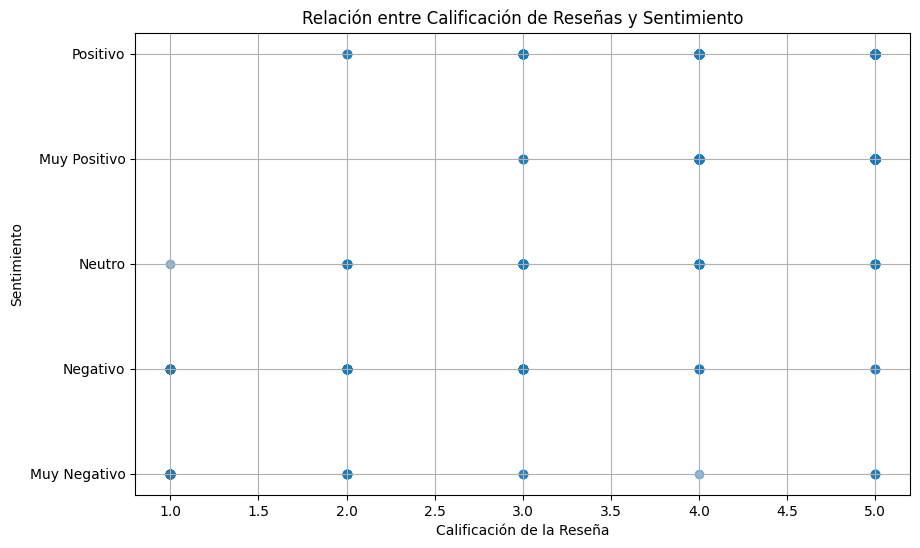

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Crear el gráfico de dispersión
plt.figure(figsize=(10, 6))
plt.scatter(data['calificaciónReseña'], data['sentimiento'], alpha=0.5)
plt.title('Relación entre Calificación de Reseñas y Sentimiento')
plt.xlabel('Calificación de la Reseña')
plt.ylabel('Sentimiento')
plt.grid(True)
plt.show()

In [13]:
import pandas as pd
from transformers import pipeline, AutoTokenizer

# Cargar el archivo CSV
df = pd.read_csv('hoteles_tra.csv')

# Nombre de la columna de texto
texto_columna = ' revisiónCuerpo'
titulo_columna = ' Título de Revisión'

# Inicializar el pipeline de análisis de sentimientos con un modelo específico
modelo = 'nlptown/bert-base-multilingual-uncased-sentiment'
analisis_sentimientos = pipeline('sentiment-analysis', model=modelo)

# Inicializar el tokenizer
tokenizer = AutoTokenizer.from_pretrained(modelo)

# Longitud máxima de secuencia permitida por el modelo
max_length = tokenizer.model_max_length

# Función para mapear las etiquetas numéricas a etiquetas descriptivas
def mapear_etiqueta(label):
    mapping = {
        '1 star': 'Muy Negativo',
        '2 stars': 'Negativo',
        '3 stars': 'Neutro',
        '4 stars': 'Positivo',
        '5 stars': 'Muy Positivo'
    }
    return mapping.get(label, 'Neutro')

# Función para analizar los sentimientos de cada texto con truncamiento
def obtener_sentimiento(texto):
    # Truncar el texto si es más largo que la longitud máxima permitida
    tokens = tokenizer(texto, truncation=True, max_length=max_length)
    texto_truncado = tokenizer.decode(tokens['input_ids'], skip_special_tokens=True)
    resultado = analisis_sentimientos(texto_truncado)[0]
    etiqueta = mapear_etiqueta(resultado['label'])
    return etiqueta, resultado['score']

# Aplicar el análisis de sentimientos a cada texto en el DataFrame
df['sentimiento'], df['puntaje'] = zip(*df[texto_columna].apply(obtener_sentimiento))
df['sentimiento_titulo'],df['puntaje_titulo'] = zip(*df[titulo_columna].apply(obtener_sentimiento))


# Mostrar los resultados
# print(df[['cuerpoReseña', 'sentimiento', 'puntaje', 'títuloReseña','sentimiento_titulo','puntaje_titulo']].head())

# Guardar los resultados en un nuevo archivo CSV
resultado_path = 'resultados_analisis_sentimientos_hoteles.csv'
df.to_csv(resultado_path, index=False)

print(f"Análisis de sentimientos completado. Los resultados se han guardado en: {resultado_path}")


c:\Users\yeiso\myenv\Lib\site-packages\huggingface_hub\file_download.py:1132: FutureWarning:

`resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.



Análisis de sentimientos completado. Los resultados se han guardado en: resultados_analisis_sentimientos_hoteles.csv


In [14]:
import pandas as pd
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos_hoteles.csv'
data = pd.read_csv(file_path)

# Limpiar el nombre de la columna para eliminar espacios adicionales
data.columns = data.columns.str.strip()

# Convertir la columna de fecha a tipo datetime
data['fecha de creacion'] = pd.to_datetime(data['fecha de creacion'], errors='coerce')

# Contar la cantidad de cada tipo de sentimiento por fecha
sentiment_counts = data.groupby(['fecha de creacion', 'sentimiento']).size().reset_index(name='counts')

# Crear el gráfico de líneas con Plotly
fig = px.line(sentiment_counts, x='fecha de creacion', y='counts', color='sentimiento',
              title='Sentimientos a lo largo del tiempo',
              labels={'fecha de creacion': 'Fecha', 'counts': 'Cantidad de Sentimientos'})

# Mostrar el gráfico
fig.show()


In [15]:
import pandas as pd
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos_hoteles.csv'
data = pd.read_csv(file_path)

# Limpiar el nombre de la columna para eliminar espacios adicionales
data.columns = data.columns.str.strip()

# Convertir la columna de fecha a tipo datetime
data['fecha de creacion'] = pd.to_datetime(data['fecha de creacion'], errors='coerce')

# Filtrar datos que tienen fechas válidas
data = data.dropna(subset=['fecha de creacion'])

# Agrupar los datos por municipio y crear gráficos individuales
municipios = data['municipio'].unique()

for municipio in municipios:
    municipio_data = data[data['municipio'] == municipio]
    
    # Contar la cantidad de cada tipo de sentimiento por fecha
    sentiment_counts = municipio_data.groupby(['fecha de creacion', 'sentimiento']).size().reset_index(name='counts')
    
    # Crear el gráfico de líneas con Plotly
    fig = px.line(sentiment_counts, x='fecha de creacion', y='counts', color='sentimiento',
                  title=f'Sentimientos a lo largo del tiempo en {municipio}',
                  labels={'fecha de creacion': 'Fecha', 'counts': 'Cantidad de Sentimientos'})
    
    # Mostrar el gráfico
    fig.show()


In [16]:
import pandas as pd
import plotly.express as px

# Cargar el archivo CSV
file_path = 'resultados_analisis_sentimientos_hoteles.csv'
data = pd.read_csv(file_path)

# Limpiar el nombre de la columna para eliminar espacios adicionales
data.columns = data.columns.str.strip()

# Convertir la columna de fecha a tipo datetime
data['fecha de creacion'] = pd.to_datetime(data['fecha de creacion'], errors='coerce')

# Filtrar datos que tienen fechas válidas
data = data.dropna(subset=['fecha de creacion'])

# Agrupar los datos por municipio y crear gráficos individuales
municipios = data['municipio'].unique()

for municipio in municipios:
    municipio_data = data[data['municipio'] == municipio]
    
    # Crear el gráfico de dispersión con Plotly
    fig = px.scatter(municipio_data, x='fecha de creacion', y='sentimiento', 
                     title=f'Sentimientos a lo largo del tiempo en {municipio}',
                     labels={'fecha de creacion': 'Fecha', 'sentimiento': 'Sentimiento'},
                     category_orders={"sentimiento": ["Muy Negativo", "Negativo", "Neutro", "Positivo", "Muy Positivo"]})
    
    # Ajustar los marcadores para mayor claridad
    fig.update_traces(marker=dict(size=10, opacity=0.6))
    
    # Mostrar el gráfico
    fig.show()


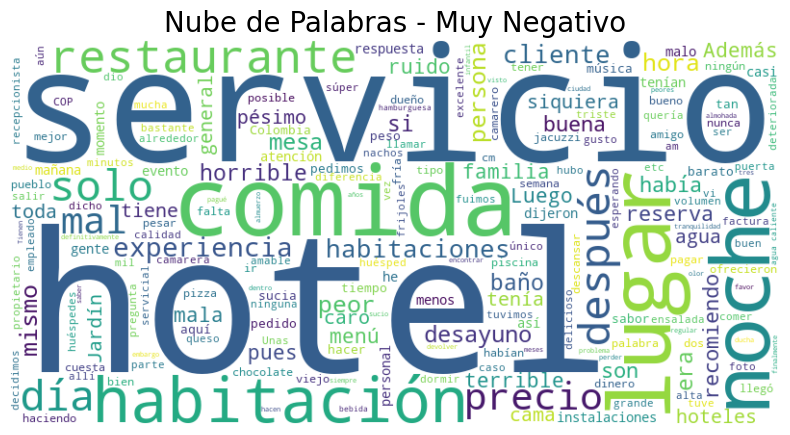

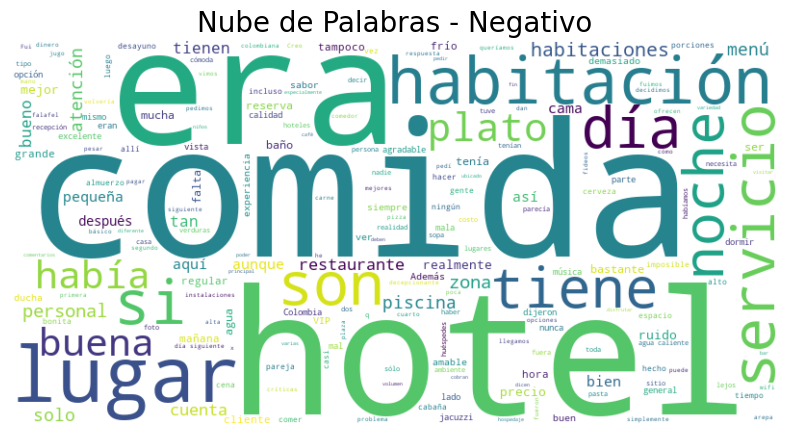

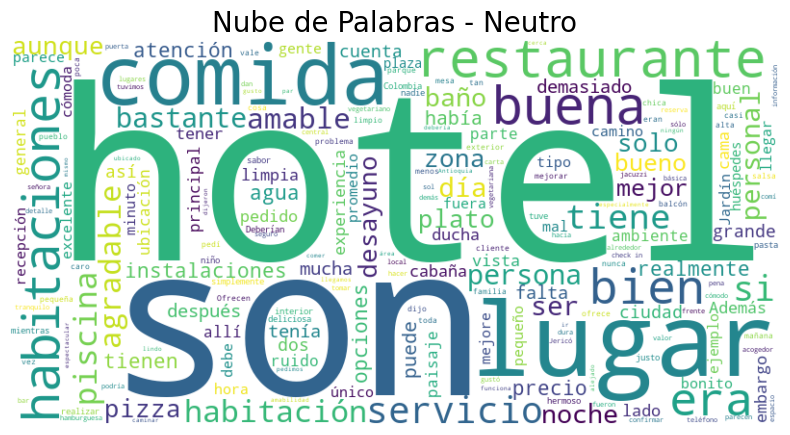

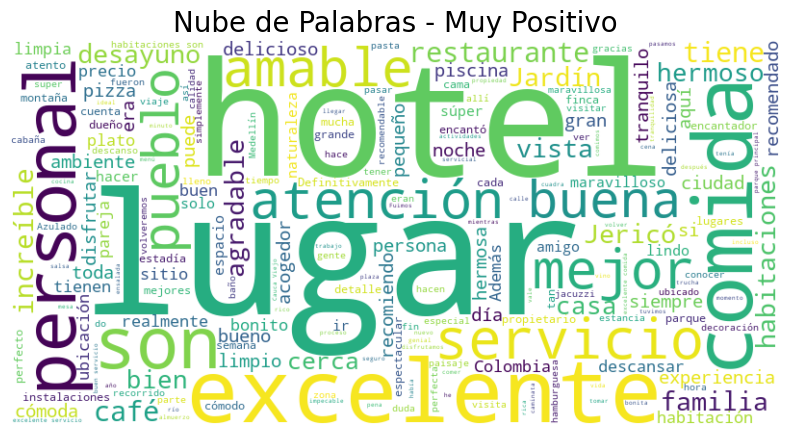

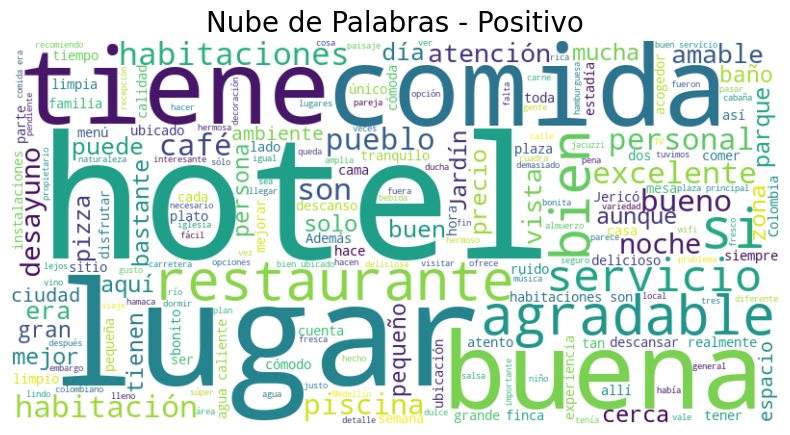

In [21]:


from wordcloud import WordCloud

file_path_sentiments = 'resultados_analisis_sentimientos.csv'
data_sentiments = pd.read_csv(file_path_sentiments)



stopwords = set([
    'de', 'la', 'que', 'el', 'en', 'y', 'a', 'los', 'del', 'se', 'las', 'por', 
    'un', 'para', 'con', 'no', 'una', 'su', 'al', 'es', 'lo', 'como', 'más', 
    'pero', 'sus', 'le', 'ya', 'o', 'fue', 'este', 'sí', 'porque', 'esta', 
    'entre', 'cuando', 'muy', 'sin', 'sobre', 'también', 'me', 'hasta', 
    'hay', 'donde', 'han', 'quien', 'están', 'estado', 'desde', 'todo', 
    'nos', 'durante', 'todos', 'uno', 'les', 'ni', 'contra', 'otros', 
    'ese', 'eso', 'ante', 'ellos', 'e', 'esto', 'mí', 'antes', 'algunos', 
    'qué', 'unos', 'yo', 'otro', 'otras', 'otra', 'él', 'tanto', 'esa', 
    'estos', 'mucho', 'quienes', 'nada', 'muchos', 'cual', 'poco', 'ella', 
    'estar', 'estas', 'algunas', 'algo', 'nosotros', 'mi', 'mis', 'tú', 
    'te', 'ti', 'tu', 'tus', 'ellas', 'nosotras', 'vosotros', 'vosotras', 
    'os', 'mío', 'mía', 'míos', 'mías', 'tuyo', 'tuya', 'tuyos', 'tuyas', 
    'suyo', 'suya', 'suyos', 'suyas', 'nuestro', 'nuestra', 'nuestros', 
    'nuestras', 'vuestro', 'vuestra', 'vuestros', 'vuestras', 'esos', 
    'esas', 'estoy', 'estás', 'está', 'estamos', 'estáis', 'están', 'esté', 
    'estés', 'estemos', 'estéis', 'estén', 'estaré', 'estarás', 'estará', 
    'estaremos', 'estaréis', 'estarán', 'estaría', 'estarías', 'estaríamos', 
    'estaríais', 'estarían', 'estaba', 'estabas', 'estábamos', 'estabais', 
    'estaban', 'estuve', 'estuviste', 'estuvo', 'estuvimos', 'estuvisteis', 
    'estuvieron', 'estuviera', 'estuvieras', 'estuviéramos', 'estuvierais', 
    'estuvieran', 'estuviese', 'estuvieses', 'estuviésemos', 'estuvieseis', 
    'estuviesen', 'estando', 'estado', 'estada', 'estados', 'estadas', 
    'estad'])

# Function to generate and plot word cloud excluding stopwords
def generate_and_plot_wordcloud(sentiment, text, stopwords):
    wordcloud = WordCloud(width=800, height=400, background_color='white', stopwords=stopwords).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Nube de Palabras - {sentiment}', fontsize=20)
    plt.show()

# Generate and plot word clouds for each sentiment excluding stopwords
for sentiment in sentiments:
    sentiment_reviews = data_sentiments[data_sentiments['sentimiento'] == sentiment]['cuerpoReseña'].dropna().astype(str)
    combined_text = " ".join(sentiment_reviews)
    generate_and_plot_wordcloud(sentiment, combined_text, stopwords)




In [52]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Cargar los datos
file_path = 'resultados_analisis_sentimientos.csv'
data = pd.read_csv(file_path)

# Crear variables dummy para la columna 'municipio'
data_dummies = pd.get_dummies(data, columns=['municipio'], drop_first=False)

# Seleccionar solo las columnas dummy y convertirlas a enteros
dummy_columns = [col for col in data_dummies.columns if col.startswith('municipio_')]
data_dummies[dummy_columns] = data_dummies[dummy_columns].astype(int)

# Convertir la variable objetivo 'sentimiento' a valores numéricos
data_dummies['sentimiento'] = data_dummies['sentimiento'].map({'Muy Negativo': 0, 'Negativo': 1, 'Neutro': 2, 'Positivo': 3, 'Muy Positivo': 4})

# Preparar los datos para la regresión logística
# Eliminar las columnas especificadas
columns_to_drop = ['títuloReseña', 'cuerpoReseña', 'idioma', 'nombre', 'sentimiento_titulo', 'puntaje', 'puntaje_titulo','sentimiento']
X = data_dummies.drop(columns=columns_to_drop)
y = data_dummies['sentimiento']

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializar y entrenar el modelo de regresión logística
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

# Realizar predicciones
y_pred = log_reg.predict(X_test)

# Evaluar el modelo
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Mostrar la precisión y el informe de clasificación
print(f'Accuracy: {accuracy}')
print(report)


Accuracy: 0.7801204819277109
              precision    recall  f1-score   support

           0       0.71      0.86      0.77        14
           1       0.38      0.23      0.29        13
           2       0.50      0.06      0.11        16
           3       0.44      0.27      0.34        55
           4       0.84      0.97      0.90       234

    accuracy                           0.78       332
   macro avg       0.57      0.48      0.48       332
weighted avg       0.73      0.78      0.74       332



c:\Users\yeiso\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



In [53]:
import numpy as np

# Get the coefficients of the logistic regression model
coefficients = log_reg.coef_

# Get the feature names
feature_names = X.columns

# Create a DataFrame with the feature importance for each class
feature_importance_df = pd.DataFrame(coefficients.T, index=feature_names, columns=['Muy Malo', 'Malo', 'Neutro', 'Bueno', 'Muy Bueno'])

# Find the top features for each class
top_features_per_class = {}
for class_name in feature_importance_df.columns:
    top_features = feature_importance_df[class_name].abs().sort_values(ascending=False).head(10)
    top_features_per_class[class_name] = top_features

top_features_per_class

{'Muy Malo': calificaciónReseña          1.744017
 calificaciónGlobal          0.561462
 municipio_Amagá             0.512523
 municipio_Andes             0.427817
 municipio_La Pintada        0.403834
 municipio_Fredonia          0.311014
 municipio_Santa Bárbara     0.244061
 municipio_Urrao             0.222398
 municipio_Ciudad Bolívar    0.144423
 municipio_Jardín            0.136855
 Name: Muy Malo, dtype: float64,
 'Malo': municipio_Amagá             1.425343
 calificaciónReseña          1.069015
 municipio_Urrao             0.648934
 municipio_Jericó            0.421258
 calificaciónGlobal          0.393211
 municipio_Santa Bárbara     0.351836
 municipio_Ciudad Bolívar    0.310305
 municipio_La Pintada        0.309521
 municipio_Andes             0.288331
 municipio_Venecia           0.276711
 Name: Malo, dtype: float64,
 'Neutro': municipio_Amagá             0.792013
 municipio_Ciudad Bolívar    0.711386
 municipio_Santa Bárbara     0.478051
 municipio_Támesis           0.399

In [61]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

# Obtener los coeficientes del modelo de regresión logística
coefficients = log_reg.coef_

# Obtener los nombres de las características
feature_names = X.columns

# Crear un DataFrame con la importancia de las características para cada clase
feature_importance_df = pd.DataFrame(coefficients.T, index=feature_names, columns=['Muy Malo', 'Malo', 'Neutro', 'Bueno', 'Muy Bueno'])

# Encontrar las características principales para cada clase
top_features_per_class = {}
for class_name in feature_importance_df.columns:
    top_features = feature_importance_df[class_name].abs().sort_values(ascending=False).head(10)
    top_features_per_class[class_name] = top_features

# Preparar los datos para la tabla
table_data = []

for class_name, top_features in top_features_per_class.items():
    for feature, importance in top_features.items():
        table_data.append([class_name, feature, importance])

# Convertir los datos en un DataFrame
table_df = pd.DataFrame(table_data, columns=['Clase', 'Característica', 'Importancia'])

# Crear la tabla con Plotly
fig = go.Figure(data=[go.Table(
    header=dict(values=list(table_df.columns),
                fill_color='paleturquoise',
                align='left'),
    cells=dict(values=[table_df.Clase, table_df.Característica, table_df.Importancia],
               fill_color='lavender',
               align='left'))
])

# Mostrar la tabla
fig.show()




In [54]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

# Obtener los coeficientes del modelo de regresión logística
coefficients = log_reg.coef_

# Obtener los nombres de las características
feature_names = X.columns

# Crear un DataFrame con la importancia de las características para cada clase
feature_importance_df = pd.DataFrame(coefficients.T, index=feature_names, columns=['Muy Malo', 'Malo', 'Neutro', 'Bueno', 'Muy Bueno'])

# Encontrar las características principales para cada clase
top_features_per_class = {}
for class_name in feature_importance_df.columns:
    top_features = feature_importance_df[class_name].abs().sort_values(ascending=False).head(10)
    top_features_per_class[class_name] = top_features

# Crear gráficos de barras para las características principales de cada clase
fig = go.Figure()

for class_name, top_features in top_features_per_class.items():
    fig.add_trace(go.Bar(
        x=top_features.index,
        y=top_features.values,
        name=class_name
    ))

# Configurar el diseño del gráfico
fig.update_layout(
    title='Top 10 características más importantes por clase',
    xaxis_title='Características',
    yaxis_title='Importancia',
    barmode='group'
)

# Mostrar el gráfico
fig.show()


In [63]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

# Obtener los coeficientes del modelo de regresión logística
coefficients = log_reg.coef_

# Obtener los nombres de las características
feature_names = X.columns

# Crear un DataFrame con la importancia de las características para cada clase
feature_importance_df = pd.DataFrame(coefficients.T, index=feature_names, columns=['Muy Malo', 'Malo', 'Neutro', 'Bueno', 'Muy Bueno'])

# Encontrar las características principales para cada clase
top_features_per_class = {}
for class_name in feature_importance_df.columns:
    top_features = feature_importance_df[class_name].abs().sort_values(ascending=False).head(10)
    top_features_per_class[class_name] = top_features

# Función para graficar las características principales para cada clase en Plotly
def plot_top_features(features, title):
    fig = go.Figure(go.Bar(
        x=features.index,
        y=features.values,
        
    ))

    fig.update_layout(
        title=title,
        xaxis_title='Características',
        yaxis_title='Coeficiente de Importancia',
        xaxis_tickangle=-45
    )

    fig.show()

# Graficar las características principales para cada clase
for class_name, top_features in top_features_per_class.items():
    plot_top_features(top_features, f'Top 10 Características para la Clase "{class_name}"')
